<a href="https://colab.research.google.com/github/too-baa/e-commerce-customer-segmentation/blob/main/CaseStudy4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import os
import datetime as dt
import pandas as pd

# 1. Set environment variables for Kaggle authentication
os.environ['KAGGLE_USERNAME'] = "KAGGLE_USERNAME"
os.environ['KAGGLE_KEY'] = "KAGGLE_KEY"

# 2. Install kaggle CLI if not already present
!pip install -q kaggle

# 3. Download and unzip the official Online Retail dataset
!kaggle datasets download -d vijayuv/onlineretail -p ./ --unzip

# 4. Read the CSV file into Pandas
# The downloaded file is named 'OnlineRetail.csv'
df = pd.read_csv("OnlineRetail.csv", encoding="ISO-8859-1")

print("Raw Dataset Shape:", df.shape)
print(df.head(3))

Dataset URL: https://www.kaggle.com/datasets/vijayuv/onlineretail
License(s): CC0-1.0
100% 7.20M/7.20M [00:00<00:00, 87.5MB/s]

Raw Dataset Shape: (541909, 8)
  InvoiceNo StockCode                         Description  Quantity  \
0    536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                 WHITE METAL LANTERN         6   
2    536365    84406B      CREAM CUPID HEARTS COAT HANGER         8   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  


In [5]:
# A. Filter out guest checkouts (missing CustomerID)
df = df.dropna(subset=['CustomerID'])

# B. Drop cancelled orders and refunds (Quantity <= 0) and zero/negative prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# C. Cast CustomerID to clean integer
df['CustomerID'] = df['CustomerID'].astype(int)

# D. Compute total revenue for each transaction line
df['TotalSpend'] = df['Quantity'] * df['UnitPrice']

# E. Parse datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# F. Set baseline date: 1 day past the latest purchase in the log
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

# G. Aggregate into customer-level RFM metrics
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency
    'InvoiceNo': 'nunique',                                  # Frequency
    'TotalSpend': 'sum'                                      # Monetary
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print("\n--- RFM Table Ready! ---")
print("Total Unique Customers:", rfm.shape[0])
print(rfm.head())


--- RFM Table Ready! ---
Total Unique Customers: 4338
   CustomerID  Recency  Frequency  Monetary
0       12346      326          1  77183.60
1       12347        2          7   4310.00
2       12348       75          4   1797.24
3       12349       19          1   1757.55
4       12350      310          1    334.40


In [6]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Inspect skewness before transformation
print("--- Skewness of Raw RFM Features (Higher > 1 means heavily skewed) ---")
print(rfm[['Recency', 'Frequency', 'Monetary']].skew())

# 2. Apply Log Transform (using log1p which computes log(1 + x) to safely handle values near 0)
rfm_log = pd.DataFrame()
rfm_log['Recency'] = np.log1p(rfm['Recency'])
rfm_log['Frequency'] = np.log1p(rfm['Frequency'])
rfm_log['Monetary'] = np.log1p(rfm['Monetary'])

print("\n--- Skewness After Log Transformation ---")
print(rfm_log.skew())

# 3. Standardize features to mean = 0, standard deviation = 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

# Convert back to DataFrame for clean inspection
X_scaled_df = pd.DataFrame(X_scaled, columns=['Recency', 'Frequency', 'Monetary'])

print("\n--- Scaled Features Head (Mean ≈ 0, Std ≈ 1) ---")
print(X_scaled_df.head())
print("\nFeature Means:", np.round(X_scaled_df.mean(), 2).to_dict())
print("Feature Stds: ", np.round(X_scaled_df.std(), 2).to_dict())

--- Skewness of Raw RFM Features (Higher > 1 means heavily skewed) ---
Recency       1.246048
Frequency    12.067031
Monetary     19.324953
dtype: float64

--- Skewness After Log Transformation ---
Recency     -0.379169
Frequency    1.208652
Monetary     0.393553
dtype: float64

--- Scaled Features Head (Mean ≈ 0, Std ≈ 1) ---
    Recency  Frequency  Monetary
0  1.461993  -0.955214  3.706225
1 -2.038734   1.074425  1.411843
2  0.373104   0.386304  0.716489
3 -0.623086  -0.955214  0.698739
4  1.424558  -0.955214 -0.618962

Feature Means: {'Recency': -0.0, 'Frequency': -0.0, 'Monetary': 0.0}
Feature Stds:  {'Recency': 1.0, 'Frequency': 1.0, 'Monetary': 1.0}


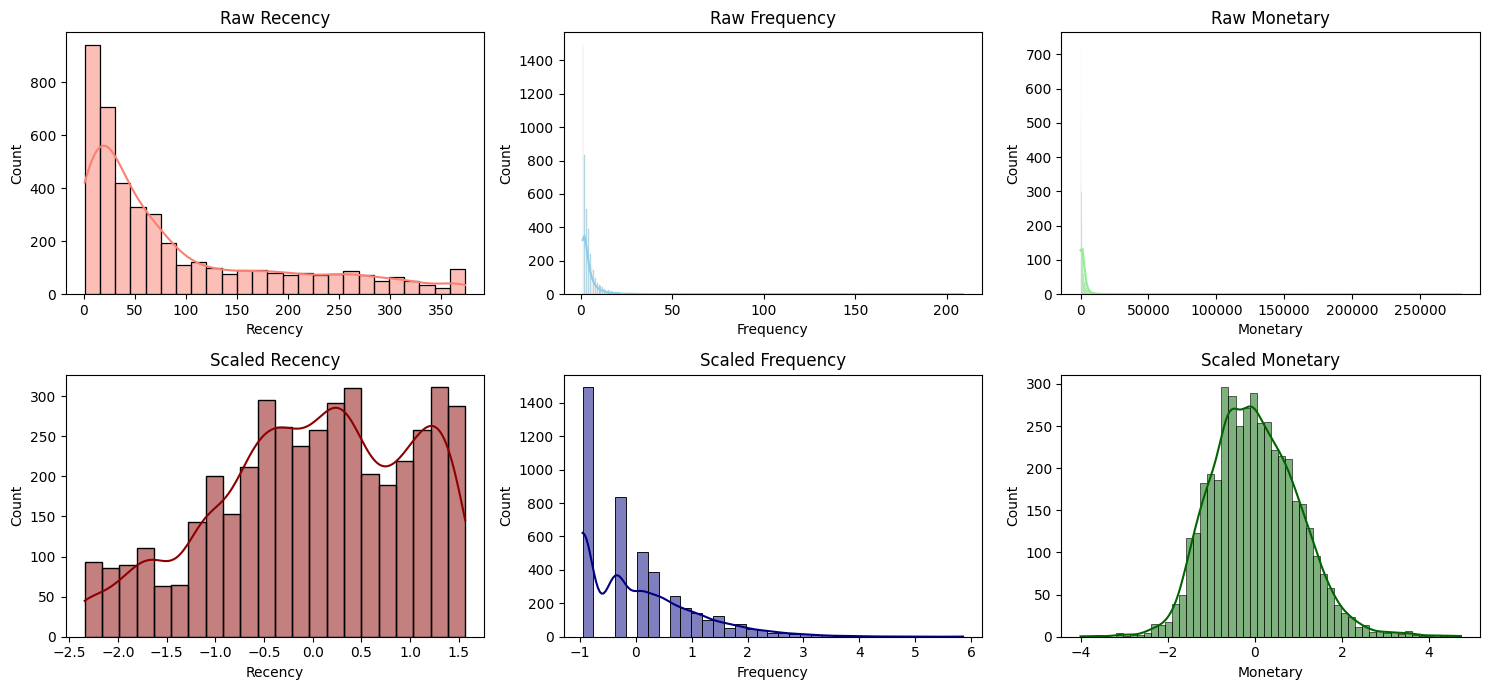

In [8]:
#optional visualisaton
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

#before transformation
sns.histplot(rfm['Recency'], kde=True, ax=axes[0, 0], color='salmon').set_title('Raw Recency')
sns.histplot(rfm['Frequency'], kde=True, ax=axes[0, 1], color='skyblue').set_title('Raw Frequency')
sns.histplot(rfm['Monetary'], kde=True, ax=axes[0, 2], color='lightgreen').set_title('Raw Monetary')

#after log transform & scaling
sns.histplot(X_scaled_df['Recency'], kde=True, ax=axes[1, 0], color='darkred').set_title('Scaled Recency')
sns.histplot(X_scaled_df['Frequency'], kde=True, ax=axes[1, 1], color='navy').set_title('Scaled Frequency')
sns.histplot(X_scaled_df['Monetary'], kde=True, ax=axes[1, 2], color='darkgreen').set_title('Scaled Monetary')

plt.tight_layout()
plt.show()

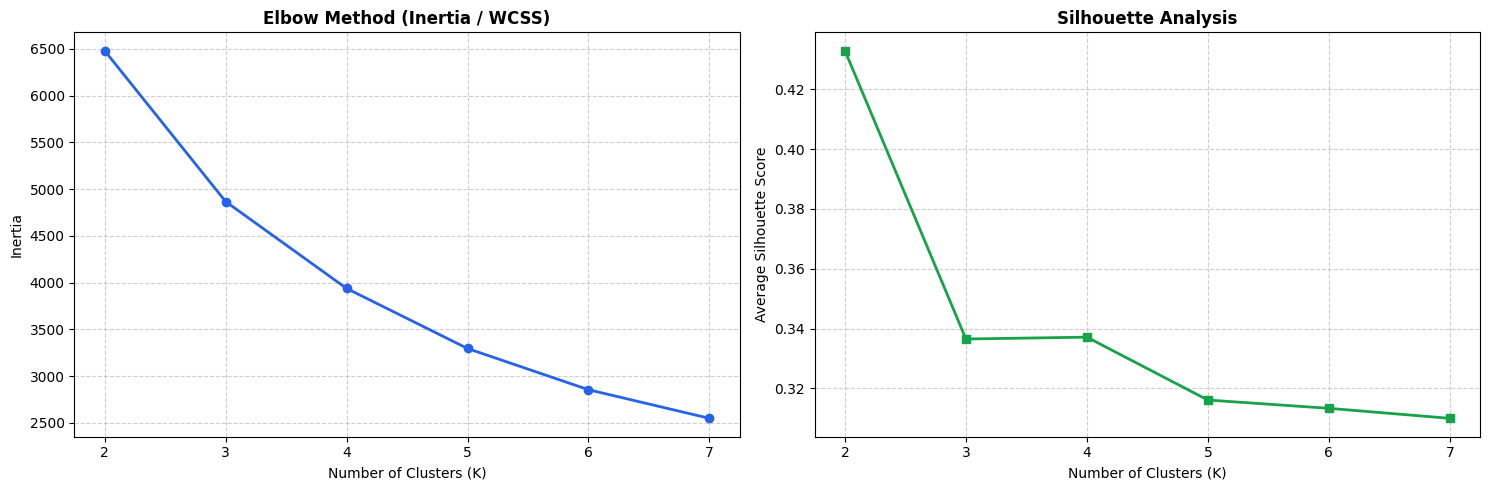

K = 2 | Inertia = 6481.2 | Silhouette Score = 0.4329
K = 3 | Inertia = 4867.8 | Silhouette Score = 0.3365
K = 4 | Inertia = 3938.5 | Silhouette Score = 0.3371
K = 5 | Inertia = 3296.0 | Silhouette Score = 0.3161
K = 6 | Inertia = 2855.0 | Silhouette Score = 0.3133
K = 7 | Inertia = 2548.9 | Silhouette Score = 0.3100


In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Test K values from 2 to 7
k_range = range(2, 8)
inertia_values = []
silhouette_values = []

for k in k_range:
    # random_state=42 guarantees reproducibility
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)

    inertia_values.append(km.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

# 2. Plot Elbow and Silhouette curves side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Curve
axes[0].plot(k_range, inertia_values, marker='o', color='#2563EB', linewidth=2)
axes[0].set_title('Elbow Method (Inertia / WCSS)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Silhouette Score Curve
axes[1].plot(k_range, silhouette_values, marker='s', color='#16A34A', linewidth=2)
axes[1].set_title('Silhouette Analysis', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Average Silhouette Score')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 3. Print the computed metrics
for k, inertia, sil in zip(k_range, inertia_values, silhouette_values):
    print(f"K = {k} | Inertia = {inertia:.1f} | Silhouette Score = {sil:.4f}")

In [10]:
from sklearn.cluster import KMeans

# 1. Fit final K-Means with K = 4
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, random_state=42)

# 2. Add the cluster assignments directly to the RFM table
rfm['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# 3. Check customer distribution across the 4 clusters
print("--- Customer Count per Cluster ---")
print(rfm['KMeans_Cluster'].value_counts().sort_index())

print("\n--- Clustered Table Preview ---")
print(rfm.head())

--- Customer Count per Cluster ---
KMeans_Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64

--- Clustered Table Preview ---
   CustomerID  Recency  Frequency  Monetary  KMeans_Cluster
0       12346      326          1  77183.60               2
1       12347        2          7   4310.00               1
2       12348       75          4   1797.24               2
3       12349       19          1   1757.55               0
4       12350      310          1    334.40               3


In [11]:
# Unscaled average RFM values for each group
cluster_summary = rfm.groupby('KMeans_Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(1)

print(cluster_summary)

               Recency Frequency Monetary      
                  mean      mean     mean count
KMeans_Cluster                                 
0                 18.1       2.1    551.8   837
1                 12.1      13.7   8074.3   716
2                 71.1       4.1   1802.8  1173
3                182.5       1.3    343.5  1612


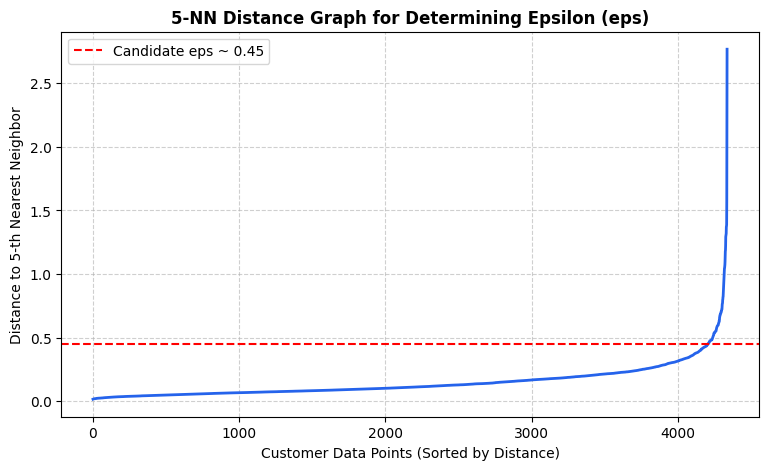

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# 1. Calculate distance to the 5th nearest neighbor for every customer
k = 5
nearest_neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = nearest_neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# 2. Sort the distances to the k-th neighbor in ascending order
sorted_distances = np.sort(distances[:, k - 1])

# 3. Plot the K-Distance Graph
plt.figure(figsize=(9, 5))
plt.plot(sorted_distances, color='#2563EB', linewidth=2)
plt.title(f'{k}-NN Distance Graph for Determining Epsilon (eps)', fontsize=12, fontweight='bold')
plt.xlabel('Customer Data Points (Sorted by Distance)')
plt.ylabel(f'Distance to {k}-th Nearest Neighbor')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(y=0.45, color='red', linestyle='--', label='Candidate eps ~ 0.45')
plt.legend()
plt.show()

In [13]:
from sklearn.cluster import DBSCAN

# 1. Fit DBSCAN using the eps identified from your knee plot
dbscan = DBSCAN(eps=0.45, min_samples=5)
rfm['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# 2. Inspect cluster sizes
print("--- Customer Count per DBSCAN Cluster ---")
print(rfm['DBSCAN_Cluster'].value_counts().sort_index())

# 3. Compare Noise (-1) vs Regular Customers (Original unscaled metrics)
dbscan_summary = rfm.groupby('DBSCAN_Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(1)

print("\n--- DBSCAN Cluster Summary (Real RFM Averages) ---")
print(dbscan_summary)

--- Customer Count per DBSCAN Cluster ---
DBSCAN_Cluster
-1      70
 0    2781
 1    1482
 2       5
Name: count, dtype: int64

--- DBSCAN Cluster Summary (Real RFM Averages) ---
               Recency Frequency Monetary      
                  mean      mean     mean count
DBSCAN_Cluster                                 
-1                62.4      30.1  39453.9    70
 0                59.2       5.3   1988.7  2781
 1               156.8       1.0    356.3  1482
 2                 9.2      35.0  18205.2     5


Explained Variance Ratio by PCA: [0.75102042 0.18759201]
Total Variance Retained by 2D PCA: 93.86%



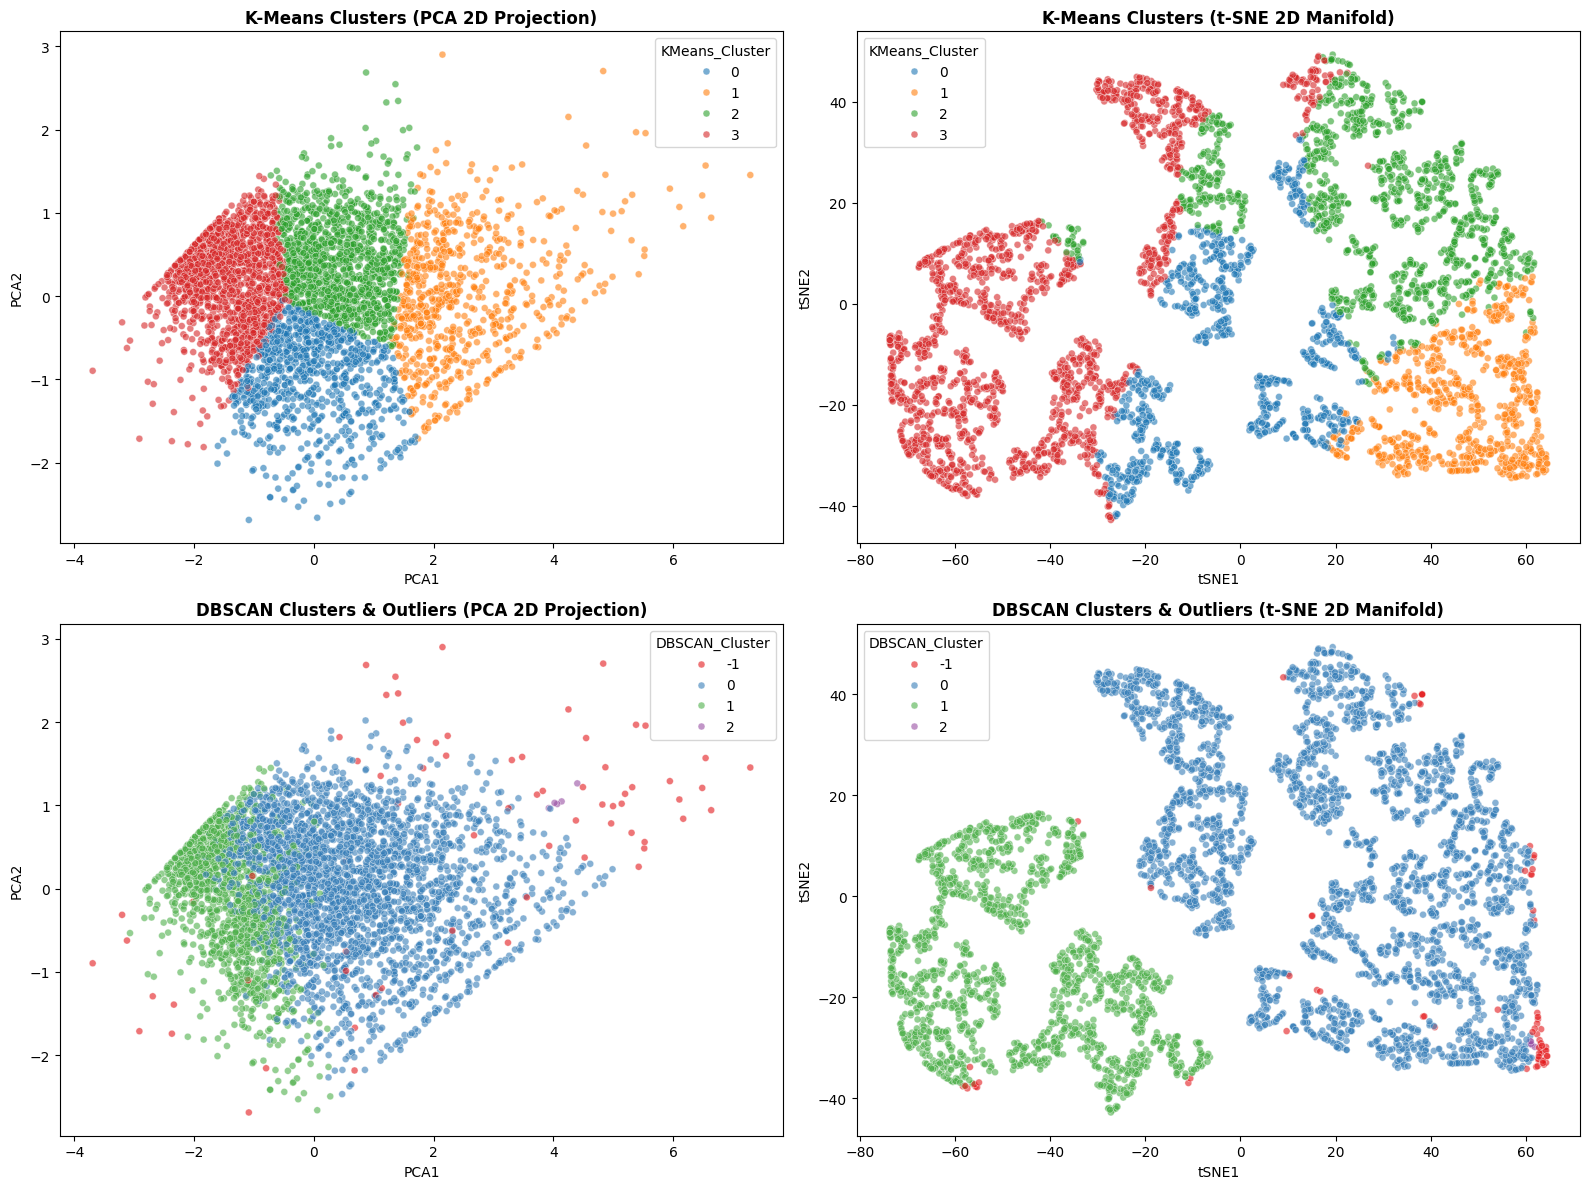

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. Apply PCA (Linear)
pca = PCA(n_components=2, random_state=42)
pca_features = pca.fit_transform(X_scaled)
rfm['PCA1'] = pca_features[:, 0]
rfm['PCA2'] = pca_features[:, 1]

print(f"Explained Variance Ratio by PCA: {pca.explained_variance_ratio_}")
print(f"Total Variance Retained by 2D PCA: {pca.explained_variance_ratio_.sum() * 100:.2f}%\n")

# 2. Apply t-SNE (Non-Linear)
# perplexity controls balance between local and global structure (typical values: 30 to 50)
tsne = TSNE(n_components=2, perplexity=40, random_state=42, max_iter=1000)
tsne_features = tsne.fit_transform(X_scaled)
rfm['tSNE1'] = tsne_features[:, 0]
rfm['tSNE2'] = tsne_features[:, 1]

# 3. Plot Comparison Visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Row 1: K-Means viewed via PCA vs t-SNE
sns.scatterplot(
    ax=axes[0, 0], data=rfm, x='PCA1', y='PCA2',
    hue='KMeans_Cluster', palette='tab10', alpha=0.6, s=25
)
axes[0, 0].set_title('K-Means Clusters (PCA 2D Projection)', fontsize=12, fontweight='bold')

sns.scatterplot(
    ax=axes[0, 1], data=rfm, x='tSNE1', y='tSNE2',
    hue='KMeans_Cluster', palette='tab10', alpha=0.6, s=25
)
axes[0, 1].set_title('K-Means Clusters (t-SNE 2D Manifold)', fontsize=12, fontweight='bold')

# Row 2: DBSCAN viewed via PCA vs t-SNE
sns.scatterplot(
    ax=axes[1, 0], data=rfm, x='PCA1', y='PCA2',
    hue='DBSCAN_Cluster', palette='Set1', alpha=0.6, s=25
)
axes[1, 0].set_title('DBSCAN Clusters & Outliers (PCA 2D Projection)', fontsize=12, fontweight='bold')

sns.scatterplot(
    ax=axes[1, 1], data=rfm, x='tSNE1', y='tSNE2',
    hue='DBSCAN_Cluster', palette='Set1', alpha=0.6, s=25
)
axes[1, 1].set_title('DBSCAN Clusters & Outliers (t-SNE 2D Manifold)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [15]:
# Aggregate unscaled RFM statistics across K-Means clusters
kmeans_summary = rfm.groupby('KMeans_Cluster').agg({
    'Recency': ['mean', 'median'],
    'Frequency': ['mean', 'median'],
    'Monetary': ['mean', 'median', 'count']
}).round(1)

print("--- K-Means Clusters Profile ---")
print(kmeans_summary)

--- K-Means Clusters Profile ---
               Recency        Frequency        Monetary              
                  mean median      mean median     mean  median count
KMeans_Cluster                                                       
0                 18.1   17.0       2.1    2.0    551.8   471.7   837
1                 12.1    8.0      13.7   10.0   8074.3  3733.9   716
2                 71.1   56.0       4.1    4.0   1802.8  1345.6  1173
3                182.5  177.0       1.3    1.0    343.5   298.3  1612


In [16]:
# 1. Map K-Means cluster numbers to the personas identified from your cluster averages
# (Verify your cluster numbers align with these indices from your kmeans_summary output)
cluster_name_map = {
    0: "Potential Loyalists",
    1: "Hibernating / At-Risk",
    2: "Champions / VIPs",
    3: "New Customers"
}

rfm['Persona'] = rfm['KMeans_Cluster'].map(cluster_name_map)

# 2. Override with DBSCAN anomaly tag for true wholesale outliers
rfm.loc[rfm['DBSCAN_Cluster'] == -1, 'Persona'] = 'B2B / Wholesale Outlier'

# 3. View persona distribution
print("--- Final Customer Persona Breakdown ---")
print(rfm['Persona'].value_counts())

# 4. Export to CSV for business/academic submission
rfm.to_csv("customer_segmentation_rfm_results.csv", index=False)
print("\nExported successfully to 'customer_segmentation_rfm_results.csv'!")

--- Final Customer Persona Breakdown ---
Persona
New Customers              1602
Champions / VIPs           1162
Potential Loyalists         829
Hibernating / At-Risk       675
B2B / Wholesale Outlier      70
Name: count, dtype: int64

Exported successfully to 'customer_segmentation_rfm_results.csv'!


Conclusion

**K-Means:** Best for day-to-day marketing because it gives every regular customer a clear group (VIPs, loyalists, new shoppers).

**DBSCAN:** Best for spotting the extremes (the giant wholesale buyers labeled -1) that need special 1-on-1 handling.